# 19 · Reviewer checks: operating characteristics, case influence, CNN against transformer (descriptive, post hoc)

**Status: descriptive and post hoc.** This notebook answers three requests from the reviews of the earlier submission. It uses the same frozen v2 predictions, the same 33 EyePACS-trained models, and the same referral rule (top f by rank; pair = higher of the two ranks) at each population's locked share. It writes a separate results file and changes nothing locked.

1. **Operating characteristics (Reviewer 3).** Sensitivity, specificity, PPV, NPV and referral rate for referable DR, plus sensitivity for severe DR, for single models and for pairs in EyePACS, DDR and BRSET. Each is reported as the mean, minimum and maximum across the 33 models and across the 495 pairs (55 architecture pairs × 9 seed combinations).
2. **Case influence (Reviewer 4).** The primary EyePACS result (net severe misses avoided against the better member, mean over 495 combinations) after removing the severe eyes that contribute most to it, one at a time up to 30. Also reported: how many such eyes must be removed before the result reaches zero, and the result after removing random severe eyes.
3. **CNN against transformer (Reviewer 4).** The benefit and the shared-miss ratio for severe DR, grouped by pair type:
   - CNN with CNN (DenseNet121, EfficientNet-B3, ResNet50);
   - CNN with transformer (ViT-Base, RETFound);
   - transformer with transformer.

   Each is shown with and without pairs from the same backbone family. Intervals come from 1,000 patient (or group) resamples with each model's referral set held fixed.

CPU, high-RAM, about 15 to 25 minutes. Only aggregate numbers are printed or written.

In [1]:
# --- setup ---
from google.colab import drive
drive.mount("/content/drive")
import os, re, json, hashlib, itertools, datetime, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
BASE = "/content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2"
PREDS, SPLITS, RESULTS, FIGS = (f"{BASE}/{d}" for d in ("03_predictions", "01_splits", "04_results", "05_figures"))
BRSET_LABELS = "/content/drive/MyDrive/stochastic_orthogonality/data/brset/label_brset.csv"
OUT_JSON = f"{RESULTS}/reviewer_checks_v2.json"
assert not os.path.exists(OUT_JSON), "this secondary analysis has already been written; rename the old output deliberately to rerun"
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
ARCHS = ["densenet121_binary", "densenet121_5class", "efficientnet_b3_binary", "efficientnet_b3_5class", "resnet50_binary", "resnet50_5class",
         "vit_base_binary", "vit_base_5class", "retfound_binary", "retfound_5class", "retfound_adversarial"]
SEEDS = [0, 1, 2]; PAIRS = list(itertools.combinations(ARCHS, 2))
def tag(k): return "" if k == 0 else f"_seed{k}"
MODELS = [(a, k) for a in ARCHS for k in SEEDS]
B, SEED = 1000, 20261028
VOLS = np.round(np.arange(0.01, 0.701, 0.01), 2)

# harm model (severe visual loss events per missed eye, one-year delay)
PDR = {"low": 0.02, "central": 0.0475, "high": 0.075}
P_HR_G3, DIRECT_G3 = 0.15, 0.002
P_PDR_G2 = {"low": 0.02, "central": 0.04, "high": 0.08}
SY = {"low": 10, "central": 15, "high": 20}; QALY_PER_BLIND_YEAR = 0.214
def svl(grade, sc):
    r = PDR[sc]
    return np.select([grade == 4, grade == 3, grade == 2], [r, P_HR_G3 * 0.5 * r + DIRECT_G3, P_PDR_G2[sc] * 0.5 * r], 0.0)
KS = np.round(np.geomspace(10, 10000, 31), 1)          # false referrals one prevented severe visual loss event is worth
LAMBDAS = np.round(np.geomspace(1e-4, 3e-2, 25), 6); BAND = (0.001, 0.004); LAM_ANCHOR = 0.0025
NPJ_GRID = {"miss": [[500, 200, 15], [250, 100, 10], [1000, 400, 20], [100, 50, 10], [50, 25, 5]], "wfp": [1, 5, 20, 50, 100]}
for sc in ("low", "central", "high"):
    print(f"{sc:>7}: per missed eye, severe visual loss events  g4 {svl(np.array(4), sc):.4f}  g3 {svl(np.array(3), sc):.4f}  g2 {svl(np.array(2), sc):.5f}"
          f"  | QALY per event {SY[sc] * QALY_PER_BLIND_YEAR:.2f}")

Mounted at /content/drive
    low: per missed eye, severe visual loss events  g4 0.0200  g3 0.0035  g2 0.00020  | QALY per event 2.14
central: per missed eye, severe visual loss events  g4 0.0475  g3 0.0056  g2 0.00095  | QALY per event 3.21
   high: per missed eye, severe visual loss events  g4 0.0750  g3 0.0076  g2 0.00300  | QALY per event 4.28


## 1. Load the three populations (frozen predictions only)

In [2]:
def pick(cols, pats, what):
    m = [c for c in cols if any(re.fullmatch(p, c, flags=re.I) for p in pats)]
    assert len(m) == 1, f"cannot identify the {what} column; columns are {list(cols)}"
    return m[0]
F_OVERRIDE = {}   # e.g. {"ddr": 0.56} if the printed f differs from the locked value
def norm(x): return pd.Series(x, dtype=str).str.replace(r"\.(jpe?g|png|tiff?)$", "", regex=True, flags=re.I).to_numpy()
HASHES = {}
def load_preds(fmt, key="image_id"):
    P = {}; ref = None
    for a, k in MODELS:
        fn = f"{PREDS}/{fmt.format(arch=a, tag=tag(k))}"; HASHES[os.path.basename(fn)] = sha256_file(fn)
        d = pd.read_csv(fn, dtype={key: str})
        if ref is None: ref = d
        else: assert (d[key].values == ref[key].values).all(), f"row order differs in {os.path.basename(fn)}"
        P[(a, k)] = d["predicted_probability"].to_numpy(np.float64)
    return ref, P
POP = {}
# EyePACS fresh set (labels and patients travel with the prediction files)
ref, P = load_preds("eyepacs_predictions_fresh_{arch}{tag}_v2.csv")
POP["eyepacs"] = {"grade": ref.true_grade.to_numpy(int), "group": ref.patient_id.astype(str).to_numpy(), "P": P, "f": 0.25}
# DDR (labels and filename groups from the intraset split written before inference)
ref, P = load_preds("ddr_predictions_{arch}{tag}_v2.csv")
sp = pd.read_csv(f"{SPLITS}/ddr_split_intraset_v2.csv", dtype={"image_id": str})
gcol, grpcol = pick(sp.columns, ["grade", "true_grade", "dr_grade", "level"], "DDR grade"), pick(sp.columns, ["group", "filename_group", "group_id"], "DDR group")
sp["_k"] = norm(sp["image_id"]); sp = sp.set_index("_k").loc[norm(ref.image_id)]
half = [c for c in sp.columns if re.fullmatch("half|split|subset", c, flags=re.I)]
g = sp[gcol].to_numpy(int); keep = g <= 4
if half:
    isA = sp[half[0]].astype(str).str.strip().str.upper().isin(["A", "HALF_A", "HALFA", "0"]).to_numpy()
    print("DDR half column:", half[0], "| values:", sorted(sp[half[0]].astype(str).unique())[:6], "| treated as half A:", int((isA & keep).sum()), "eyes")
else:
    isA = np.ones(len(g), bool); print("WARNING: no DDR half column found; f uses the whole DDR prevalence")
prevA = float((g[keep & isA] >= 2).mean())
POP["ddr"] = {"grade": g[keep], "group": sp[grpcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}, "f": round(1.31 * prevA, 4)}
# BRSET (labels read from the BRSET label file; only aggregates leave this runtime)
ref, P = load_preds("brset_predictions_eyepacs_{arch}{tag}_v2.csv")
lb = pd.read_csv(BRSET_LABELS, dtype=str)
icol, pcol, idcol = pick(lb.columns, [r".*icdr.*"], "BRSET ICDR grade"), pick(lb.columns, ["patient_id", "patient"], "BRSET patient"), pick(lb.columns, ["image_id", "image"], "BRSET image id")
lb["_k"] = norm(lb[idcol]); lb = lb.set_index("_k").loc[norm(ref.image_id)]
g = pd.to_numeric(lb[icol], errors="coerce").to_numpy(); keep = np.isin(g, [0, 1, 2, 3, 4])
POP["brset"] = {"grade": g[keep].astype(int), "group": lb[pcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}}
POP["brset"]["f"] = round(1.31 * float((POP["brset"]["grade"] >= 2).mean()), 4)
for name, v in F_OVERRIDE.items(): POP[name]["f"] = v
for name, d in POP.items():
    gr = d["grade"]
    print(f"{name:>8}: {len(gr):,} eyes | {len(set(d['group'])):,} groups | referable {np.mean(gr >= 2):.3f} | grade 3 {int((gr == 3).sum())} | grade 4 {int((gr == 4).sum())} | f = {d['f']}")
print("expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075")

DDR half column: half | values: ['A', 'B'] | treated as half A: 6205 eyes
 eyepacs: 15,794 eyes | 7,897 groups | referable 0.195 | grade 3 384 | grade 4 328 | f = 0.25
     ddr: 12,422 eyes | 332 groups | referable 0.453 | grade 3 236 | grade 4 913 | f = 0.555
   brset: 16,266 eyes | 8,524 groups | referable 0.057 | grade 3 78 | grade 4 396 | f = 0.0745
expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075


## 2. Referral sets at the locked share

In [3]:
FAMILY = {a: a.split("_")[0] for a in ARCHS}
KIND = {a: ("transformer" if FAMILY[a] in ("vit", "retfound") else "CNN") for a in ARCHS}
SETS = {}
for name, d in POP.items():
    n = len(d["grade"]); R = {m: rankdata(p) / n for m, p in d["P"].items()}; k = int(round(d["f"] * n))
    def top(score): o = np.argsort(-score, kind="stable"); s = np.zeros(n, bool); s[o[:k]] = True; return s
    single = {m: top(R[m]) for m in MODELS}
    pair = {(ma, mb): top(np.maximum(R[ma], R[mb]) + 1e-9 * np.minimum(R[ma], R[mb]))
            for a, b in PAIRS for i in SEEDS for j in SEEDS for ma, mb in [((a, i), (b, j))]}
    SETS[name] = {"single": single, "pair": pair, "R": R, "k": k}
    print(f"{name}: {k:,} of {n:,} referred (f = {d['f']}); {len(single)} single sets, {len(pair)} pair sets")

eyepacs: 3,948 of 15,794 referred (f = 0.25); 33 single sets, 495 pair sets
ddr: 6,894 of 12,422 referred (f = 0.555); 33 single sets, 495 pair sets
brset: 1,212 of 16,266 referred (f = 0.0745); 33 single sets, 495 pair sets


## 3. Operating characteristics (Reviewer 3)

In [4]:
def opchars(ref, g):
    pos, sev = g >= 2, g >= 3
    tp = (ref & pos).sum(); fp = (ref & ~pos).sum(); fn = (~ref & pos).sum(); tn = (~ref & ~pos).sum()
    return {"sensitivity_referable": tp / (tp + fn), "specificity": tn / (tn + fp), "PPV": tp / (tp + fp), "NPV": tn / (tn + fn),
            "referral_rate": ref.mean(), "sensitivity_severe": (ref & sev).sum() / sev.sum()}
rows = []
for name, d in POP.items():
    g = d["grade"]
    for kind in ("single", "pair"):
        df = pd.DataFrame([opchars(s, g) for s in SETS[name][kind].values()])
        for col in df.columns:
            rows.append({"population": name, "reader": "single model (33)" if kind == "single" else "pair (495)", "measure": col,
                         "mean": df[col].mean(), "min": df[col].min(), "max": df[col].max()})
OC = pd.DataFrame(rows); OC.to_csv(f"{RESULTS}/reviewer_opchars_v2.csv", index=False)
OC["cell"] = OC.apply(lambda x: f"{100*x['mean']:.1f}% ({100*x['min']:.1f} to {100*x['max']:.1f})", axis=1)
pd.set_option("display.width", 220, "display.max_colwidth", 40)
display(OC.pivot_table(index=["population", "measure"], columns="reader", values="cell", aggfunc="first"))
print("Referral rate is fixed by design, so pairs and singles refer the same number of eyes; differences show where the referrals go.")

reader                                      pair (495)     single model (33)
population measure                                                          
brset      NPV                    98.7% (98.0 to 99.0)  98.5% (97.4 to 98.8)
           PPV                    59.8% (51.7 to 64.1)  57.6% (44.6 to 61.7)
           referral_rate             7.5% (7.5 to 7.5)     7.5% (7.5 to 7.5)
           sensitivity_referable  78.4% (67.8 to 84.0)  75.5% (58.5 to 80.9)
           sensitivity_severe     90.0% (75.7 to 96.0)  86.7% (65.0 to 95.6)
           specificity            96.8% (96.2 to 97.2)  96.7% (95.6 to 97.0)
ddr        NPV                    87.3% (84.1 to 90.6)  85.5% (83.5 to 90.1)
           PPV                    71.4% (68.9 to 74.1)  70.0% (68.4 to 73.7)
           referral_rate          55.5% (55.5 to 55.5)  55.5% (55.5 to 55.5)
           sensitivity_referable  87.5% (84.4 to 90.8)  85.8% (83.8 to 90.3)
           sensitivity_severe     97.0% (95.0 to 98.3)  95.9% (93.1 to 97.7)
           specificity            71.0% (68.4 to 73.7)  69.6% (68.0 to 73.3)
eyepacs    NPV                    93.3% (92.3 to 94.1)  92.7% (91.7 to 93.6)
           PPV                    58.0% (55.2 to 60.4)  56.2% (53.3 to 59.0)
           referral_rate          25.0% (25.0 to 25.0)  25.0% (25.0 to 25.0)
           sensitivity_referable  74.3% (70.6 to 77.3)  71.9% (68.3 to 75.5)
           sensitivity_severe     95.4% (92.7 to 97.1)  93.9% (91.4 to 96.5)
           specificity            87.0% (86.1 to 87.7)  86.4% (85.5 to 87.3)

Referral rate is fixed by design, so pairs and singles refer the same number of eyes; differences show where the referrals go.


## 4. Case influence on the primary result (Reviewer 4)
Contribution of each severe eye: in each of the 495 combinations, +1 if the better member missed it and the pair caught it, −1 if the reverse. The better member is the one with fewer severe misses in that combination. Summed over combinations and divided by 495, these contributions reproduce the primary statistic exactly. Eyes are then removed from the population in order of contribution, the ranks and referral sets are recomputed from scratch, and the statistic is recalculated.

primary, all eyes: 4.739 net severe eyes per pair (lock v3: 4.741); sum of contributions: 4.739
 removed  net_severe_avoided
       0               4.739
       1               4.384
       2               4.055
       3               3.709
       5               3.174
      10               2.220
      15               1.626
      20               1.139
      25               0.711
      30               0.376
most influential severe eyes removed before the result reaches zero: more than 30 (of 712 severe eyes)
random 5 severe eyes removed (20 draws): mean 4.691 (range 4.331 to 4.800)
random 10 severe eyes removed (20 draws): mean 4.643 (range 4.366 to 4.877)
random 20 severe eyes removed (20 draws): mean 4.647 (range 4.345 to 4.956)


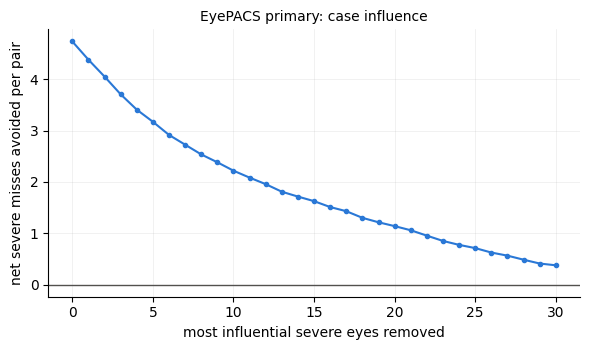

In [5]:
def primary(d, keep):
    g = d["grade"][keep]; n = len(g); k = int(round(d["f"] * n)); sev = g >= 3
    R = {m: rankdata(p[keep]) / n for m, p in d["P"].items()}
    def top(score): o = np.argsort(-score, kind="stable"); s = np.zeros(n, bool); s[o[:k]] = True; return s
    miss = {m: (~top(R[m]) & sev).sum() for m in MODELS}
    vals = []
    for a, b in PAIRS:
        for i in SEEDS:
            for j in SEEDS:
                ma, mb = (a, i), (b, j); ps = top(np.maximum(R[ma], R[mb]) + 1e-9 * np.minimum(R[ma], R[mb]))
                vals.append(min(miss[ma], miss[mb]) - (~ps & sev).sum())
    return float(np.mean(vals))
d = POP["eyepacs"]; g = d["grade"]; S = SETS["eyepacs"]; sev_idx = np.where(g >= 3)[0]
contrib = np.zeros(len(g))
miss_s = {m: ~S["single"][m] & (g >= 3) for m in MODELS}
for (ma, mb), ps in S["pair"].items():
    better = ma if miss_s[ma].sum() <= miss_s[mb].sum() else mb
    contrib += (miss_s[better] & ps).astype(float) - (~ps & (g >= 3) & ~miss_s[better]).astype(float)
contrib /= len(S["pair"])
base = primary(d, np.ones(len(g), bool))
print(f"primary, all eyes: {base:.3f} net severe eyes per pair (lock v3: 4.741); sum of contributions: {contrib.sum():.3f}")
order = sev_idx[np.argsort(-contrib[sev_idx])]
infl = [{"removed": 0, "net_severe_avoided": base}]; zero_at = None
for k in range(1, 31):
    keep = np.ones(len(g), bool); keep[order[:k]] = False; v = primary(d, keep); infl.append({"removed": k, "net_severe_avoided": v})
    if zero_at is None and v <= 0: zero_at = k
INF = pd.DataFrame(infl); INF.to_csv(f"{RESULTS}/reviewer_case_influence_v2.csv", index=False)
print(INF.iloc[[0, 1, 2, 3, 5, 10, 15, 20, 25, 30]].round(3).to_string(index=False))
print(f"most influential severe eyes removed before the result reaches zero: {zero_at if zero_at else 'more than 30'} (of {len(sev_idx)} severe eyes)")
rng = np.random.default_rng(20261029); RAND = {}
for k in (5, 10, 20):
    v = [primary(d, np.isin(np.arange(len(g)), rng.choice(sev_idx, k, replace=False), invert=True)) for _ in range(20)]
    RAND[k] = (float(np.mean(v)), float(np.min(v)), float(np.max(v)))
    print(f"random {k} severe eyes removed (20 draws): mean {RAND[k][0]:.3f} (range {RAND[k][1]:.3f} to {RAND[k][2]:.3f})")
plt.figure(figsize=(6, 3.6)); plt.plot(INF.removed, INF.net_severe_avoided, marker="o", ms=3, color="#2a78d6"); plt.axhline(0, color="#52514e", lw=1)
plt.xlabel("most influential severe eyes removed"); plt.ylabel("net severe misses avoided per pair"); plt.title("EyePACS primary: case influence", fontsize=10)
plt.grid(alpha=0.25, lw=0.5); [plt.gca().spines[s].set_visible(False) for s in ("top", "right")]; plt.tight_layout()
plt.savefig(f"{FIGS}/reviewer_case_influence_v2.png", dpi=200); plt.show()

## 5. CNN against transformer (Reviewer 4)
Per pair, at the locked share:
- **Benefit:** net severe misses avoided against the better member, per 10,000 eyes.
- **Shared-miss ratio:** the share of severe eyes both members miss, divided by the product of their separate severe miss rates.

Group means are taken over all pair and seed combinations in the group. Intervals come from 1,000 patient (or group) resamples with every referral set held fixed. "Excluding same family" drops pairs that share a backbone, such as the two DenseNet121 formulations or the three RETFound variants.

In [6]:
GROUPS = {"CNN with CNN": ("CNN", "CNN"), "CNN with transformer": ("CNN", "transformer"), "transformer with transformer": ("transformer", "transformer")}
rows = []
for name, d in POP.items():
    g = d["grade"]; sev = g >= 3; S = SETS[name]; n = len(g)
    codes = pd.factorize(d["group"])[0]; G = codes.max() + 1; rng = np.random.default_rng(SEED)
    W = np.vstack([np.ones(n)] + [np.bincount(rng.integers(0, G, G), minlength=G)[codes] for _ in range(B)]).astype(np.float32)
    msingle = {m: (W @ (~S["single"][m] & sev).astype(np.float32)) for m in MODELS}          # weighted severe misses per resample
    nsev = W @ sev.astype(np.float32)
    per = {}
    for (ma, mb), ps in S["pair"].items():
        ka, kb = KIND[ma[0]], KIND[mb[0]]; grp = next(gn for gn, kk in GROUPS.items() if sorted((ka, kb)) == sorted(kk))
        same_fam = FAMILY[ma[0]] == FAMILY[mb[0]]
        pm = W @ (~ps & sev).astype(np.float32); both = W @ ((~S["single"][ma]) & (~S["single"][mb]) & sev).astype(np.float32)
        benefit = (np.minimum(msingle[ma], msingle[mb]) - pm) / W.sum(1) * 1e4
        ratio = (both / nsev) / ((msingle[ma] / nsev) * (msingle[mb] / nsev) + 1e-12)
        for key in [(grp, "all pairs")] + ([] if same_fam else [(grp, "excluding same family")]):
            per.setdefault(key, {"benefit": [], "ratio": []}); per[key]["benefit"].append(benefit); per[key]["ratio"].append(ratio)
    for (grp, sub), v in per.items():
        for meas in ("benefit", "ratio"):
            x = np.mean(np.stack(v[meas]), 0)
            rows.append({"population": name, "group": grp, "subset": sub, "measure": "net severe misses avoided per 10,000" if meas == "benefit" else "shared-miss ratio, severe DR",
                         "combinations": len(v[meas]), "estimate": float(x[0]), "ci_lo": float(np.percentile(x[1:], 2.5)), "ci_hi": float(np.percentile(x[1:], 97.5))})
CT = pd.DataFrame(rows); CT.to_csv(f"{RESULTS}/reviewer_cnn_transformer_v2.csv", index=False)
CT["cell"] = CT.apply(lambda x: f"{x.estimate:.2f} ({x.ci_lo:.2f} to {x.ci_hi:.2f}); n={x.combinations}", axis=1)
for meas in CT.measure.unique():
    print(f"\n=== {meas} ==="); display(CT[CT.measure == meas].pivot_table(index=["group", "subset"], columns="population", values="cell", aggfunc="first"))


=== net severe misses avoided per 10,000 ===


population                                                                  brset                         ddr                     eyepacs
group                        subset                                                                                                      
CNN with CNN                 all pairs              -1.77 (-4.17 to -0.11); n=135  4.77 (1.87 to 6.93); n=135  4.41 (2.53 to 5.67); n=135
                             excluding same family  -2.64 (-5.19 to -0.72); n=108  5.00 (1.85 to 7.32); n=108  4.67 (2.69 to 6.14); n=108
CNN with transformer         all pairs               -1.71 (-3.98 to 0.14); n=270  3.72 (1.16 to 5.77); n=270  3.09 (0.98 to 4.53); n=270
                             excluding same family   -1.71 (-3.98 to 0.14); n=270  3.72 (1.16 to 5.77); n=270  3.09 (0.98 to 4.53); n=270
transformer with transformer all pairs               -2.30 (-4.61 to -0.21); n=90  2.50 (-0.20 to 5.07); n=90  0.62 (-1.20 to 1.88); n=90
                             excluding same family    -3.23 (-6.78 to 0.00); n=54  3.77 (-0.07 to 7.54); n=54  0.54 (-2.02 to 2.84); n=54


=== shared-miss ratio, severe DR ===


population                                                               brset                           ddr                      eyepacs
group                        subset                                                                                                      
CNN with CNN                 all pairs              3.53 (3.09 to 4.15); n=135  10.14 (8.14 to 13.12); n=135   7.88 (6.66 to 9.63); n=135
                             excluding same family  3.38 (2.95 to 3.97); n=108   9.65 (7.82 to 12.31); n=108   7.55 (6.35 to 9.23); n=108
CNN with transformer         all pairs              3.73 (3.17 to 4.50); n=270  10.57 (8.01 to 13.82); n=270  8.00 (6.59 to 10.07); n=270
                             excluding same family  3.73 (3.17 to 4.50); n=270  10.57 (8.01 to 13.82); n=270  8.00 (6.59 to 10.07); n=270
transformer with transformer all pairs               6.22 (5.08 to 7.99); n=90  16.96 (12.32 to 26.00); n=90  11.97 (9.48 to 16.39); n=90
                             excluding same family   4.24 (3.31 to 5.48); n=54   11.21 (8.22 to 14.86); n=54   9.11 (7.06 to 12.39); n=54

## 6. Write the results record

In [7]:
REC = {"status": "descriptive, post hoc; answers reviewer requests; not specified in a dated lock", "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
       "referral_rule": "top f by within-population rank; pair = higher of the two ranks; f as locked per population",
       "populations": {n: {"eyes": int(len(d["grade"])), "f": d["f"]} for n, d in POP.items()},
       "operating_characteristics": OC.drop(columns="cell").to_dict("records"),
       "case_influence": {"primary_all_eyes": base, "removal_curve": INF.to_dict("records"), "influential_eyes_to_reach_zero": zero_at,
                          "severe_eyes": int(len(sev_idx)), "random_removal": RAND},
       "cnn_vs_transformer": CT.drop(columns="cell").to_dict("records"), "input_sha256": HASHES}
with open(OUT_JSON, "w") as fh: json.dump(REC, fh, indent=1, default=float)
print("written", OUT_JSON)

written /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/reviewer_checks_v2.json
